In [1]:
import pandas as pd
import plotly.express as px
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.preprocessing import normalize,StandardScaler
import numpy as np
import shap
from xgboost import XGBClassifier

C:\Users\gupta\anaconda3\envs\project_new\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
df = pd.read_csv('Dataset/Titanic-Dataset.csv')

In [3]:
df

,Name,Sex,Age,SibSp,Parch,Embarked,Ticket,Fare,Cabin,PassengerId,Pclass,Survived
0,"Braund, Mr. Owen Harris",male,22.0,1,0,S,A/5 21171,7.2500,NaN,1,3,0
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,C,PC 17599,71.2833,C85,2,1,1
2,"Heikkinen, Miss. Laina",female,26.0,0,0,S,STON/O2. 3101282,7.9250,NaN,3,3,1
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,S,113803,53.1000,C123,4,1,1
4,"Allen, Mr. William Henry",male,35.0,0,0,S,373450,8.0500,NaN,5,3,0
...,...,...,...,...,...,...,...,...,...,...,...,...
886,"Montvila, Rev. Juozas",male,27.0,0,0,S,211536,13.0000,NaN,887,2,0
887,"Graham, Miss. Margaret Edith",female,19.0,0,0,S,112053,30.0000,B42,888,1,1
888,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,S,W./C. 6607,23.4500,NaN,889,3,0
889,"Behr, Mr. Karl Howell",male,26.0,0,0,C,111369,30.0000,C148,890,1,1


# Data exploration and analysis


In [61]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Name         891 non-null    str    
 1   Sex          891 non-null    str    
 2   Age          714 non-null    float64
 3   SibSp        891 non-null    int64  
 4   Parch        891 non-null    int64  
 5   Embarked     889 non-null    str    
 6   Ticket       891 non-null    str    
 7   Fare         891 non-null    float64
 8   Cabin        204 non-null    str    
 9   PassengerId  891 non-null    int64  
 10  Pclass       891 non-null    int64  
 11  Survived     891 non-null    int64  
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [62]:
df.shape

(891, 12)

In [63]:
df.columns

Index(['Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Embarked', 'Ticket', 'Fare',
       'Cabin', 'PassengerId', 'Pclass', 'Survived'],
      dtype='str')

In [64]:
df.describe()

,Age,SibSp,Parch,Fare,PassengerId,Pclass,Survived
count,714.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,29.699118,0.523008,0.381594,32.204208,446.000000,2.308642,0.383838
std,14.526497,1.102743,0.806057,49.693429,257.353842,0.836071,0.486592
min,0.420000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000
25%,20.125000,0.000000,0.000000,7.910400,223.500000,2.000000,0.000000
50%,28.000000,0.000000,0.000000,14.454200,446.000000,3.000000,0.000000
75%,38.000000,1.000000,0.000000,31.000000,668.500000,3.000000,1.000000
max,80.000000,8.000000,6.000000,512.329200,891.000000,3.000000,1.000000


## NAN and duplicates

In [65]:
df.isna().any()

Name           False
Sex            False
Age             True
SibSp          False
Parch          False
Embarked        True
Ticket         False
Fare           False
Cabin           True
PassengerId    False
Pclass         False
Survived       False
dtype: bool

In [66]:
df.isna().sum()

Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Embarked         2
Ticket           0
Fare             0
Cabin          687
PassengerId      0
Pclass           0
Survived         0
dtype: int64

In [67]:
[df.duplicated().sum()]

[np.int64(0)]

In [68]:
df[df.isna().any(axis=1)]

,Name,Sex,Age,SibSp,Parch,Embarked,Ticket,Fare,Cabin,PassengerId,Pclass,Survived
0,"Braund, Mr. Owen Harris",male,22.0,1,0,S,A/5 21171,7.2500,NaN,1,3,0
2,"Heikkinen, Miss. Laina",female,26.0,0,0,S,STON/O2. 3101282,7.9250,NaN,3,3,1
4,"Allen, Mr. William Henry",male,35.0,0,0,S,373450,8.0500,NaN,5,3,0
5,"Moran, Mr. James",male,NaN,0,0,Q,330877,8.4583,NaN,6,3,0
7,"Palsson, Master. Gosta Leonard",male,2.0,3,1,S,349909,21.0750,NaN,8,3,0
...,...,...,...,...,...,...,...,...,...,...,...,...
884,"Sutehall, Mr. Henry Jr",male,25.0,0,0,S,SOTON/OQ 392076,7.0500,NaN,885,3,0
885,"Rice, Mrs. William (Margaret Norton)",female,39.0,0,5,Q,382652,29.1250,NaN,886,3,0
886,"Montvila, Rev. Juozas",male,27.0,0,0,S,211536,13.0000,NaN,887,2,0
888,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,S,W./C. 6607,23.4500,NaN,889,3,0


In [69]:
df[df['Embarked'].isna()]

,Name,Sex,Age,SibSp,Parch,Embarked,Ticket,Fare,Cabin,PassengerId,Pclass,Survived
61,"Icard, Miss. Amelie",female,38.0,0,0,NaN,113572,80.0,B28,62,1,1
829,"Stone, Mrs. George Nelson (Martha Evelyn)",female,62.0,0,0,NaN,113572,80.0,B28,830,1,1


In [70]:
df[df['Cabin']=='B28']

,Name,Sex,Age,SibSp,Parch,Embarked,Ticket,Fare,Cabin,PassengerId,Pclass,Survived
61,"Icard, Miss. Amelie",female,38.0,0,0,NaN,113572,80.0,B28,62,1,1
829,"Stone, Mrs. George Nelson (Martha Evelyn)",female,62.0,0,0,NaN,113572,80.0,B28,830,1,1


In [71]:
df[df['Ticket']=='113572']

,Name,Sex,Age,SibSp,Parch,Embarked,Ticket,Fare,Cabin,PassengerId,Pclass,Survived
61,"Icard, Miss. Amelie",female,38.0,0,0,NaN,113572,80.0,B28,62,1,1
829,"Stone, Mrs. George Nelson (Martha Evelyn)",female,62.0,0,0,NaN,113572,80.0,B28,830,1,1


In [72]:
df.drop([61,829],inplace=True)

In [73]:
df.sort_values(by="Age",ascending=False)

,Name,Sex,Age,SibSp,Parch,Embarked,Ticket,Fare,Cabin,PassengerId,Pclass,Survived
630,"Barkworth, Mr. Algernon Henry Wilson",male,80.0,0,0,S,27042,30.0000,A23,631,1,1
851,"Svensson, Mr. Johan",male,74.0,0,0,S,347060,7.7750,NaN,852,3,0
96,"Goldschmidt, Mr. George B",male,71.0,0,0,C,PC 17754,34.6542,A5,97,1,0
493,"Artagaveytia, Mr. Ramon",male,71.0,0,0,C,PC 17609,49.5042,NaN,494,1,0
116,"Connors, Mr. Patrick",male,70.5,0,0,Q,370369,7.7500,NaN,117,3,0
...,...,...,...,...,...,...,...,...,...,...,...,...
859,"Razi, Mr. Raihed",male,NaN,0,0,C,2629,7.2292,NaN,860,3,0
863,"Sage, Miss. Dorothy Edith ""Dolly""",female,NaN,8,2,S,CA. 2343,69.5500,NaN,864,3,0
868,"van Melkebeke, Mr. Philemon",male,NaN,0,0,S,345777,9.5000,NaN,869,3,0
878,"Laleff, Mr. Kristo",male,NaN,0,0,S,349217,7.8958,NaN,879,3,0


<Axes: xlabel='Age', ylabel='Count'>

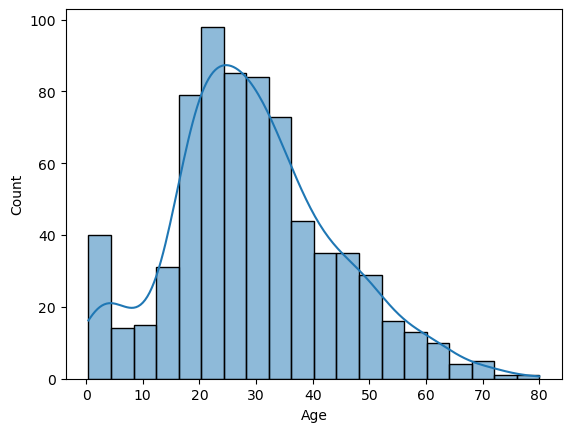

In [74]:
sns.histplot(df,x="Age",kde=True)

# Age and survival relation

In [75]:
df[df['Fare'] > 400]

,Name,Sex,Age,SibSp,Parch,Embarked,Ticket,Fare,Cabin,PassengerId,Pclass,Survived
258,"Ward, Miss. Anna",female,35.0,0,0,C,PC 17755,512.3292,NaN,259,1,1
679,"Cardeza, Mr. Thomas Drake Martinez",male,36.0,0,1,C,PC 17755,512.3292,B51 B53 B55,680,1,1
737,"Lesurer, Mr. Gustave J",male,35.0,0,0,C,PC 17755,512.3292,B101,738,1,1


In [76]:
surv_count = df['Survived'].value_counts() 

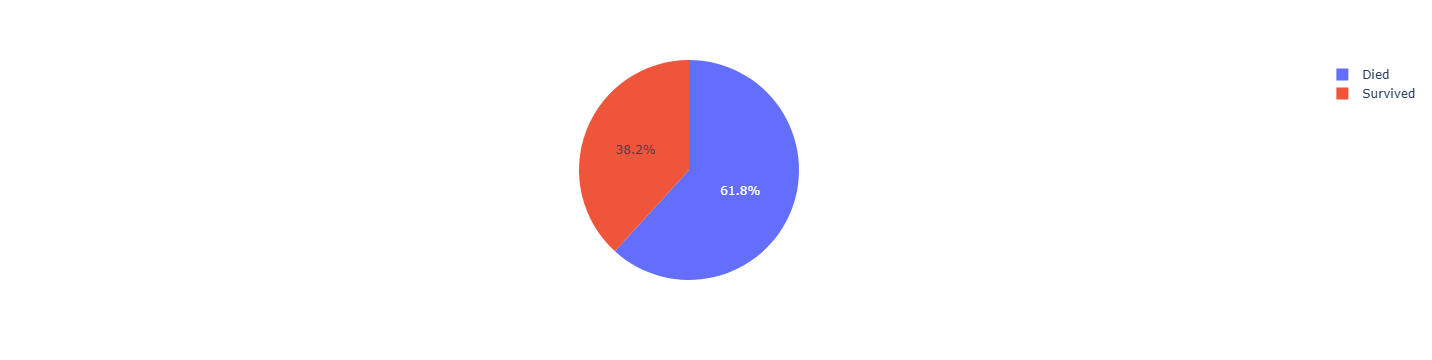

In [77]:
px.pie(surv_count,values=surv_count.values,names=['Died','Survived'])

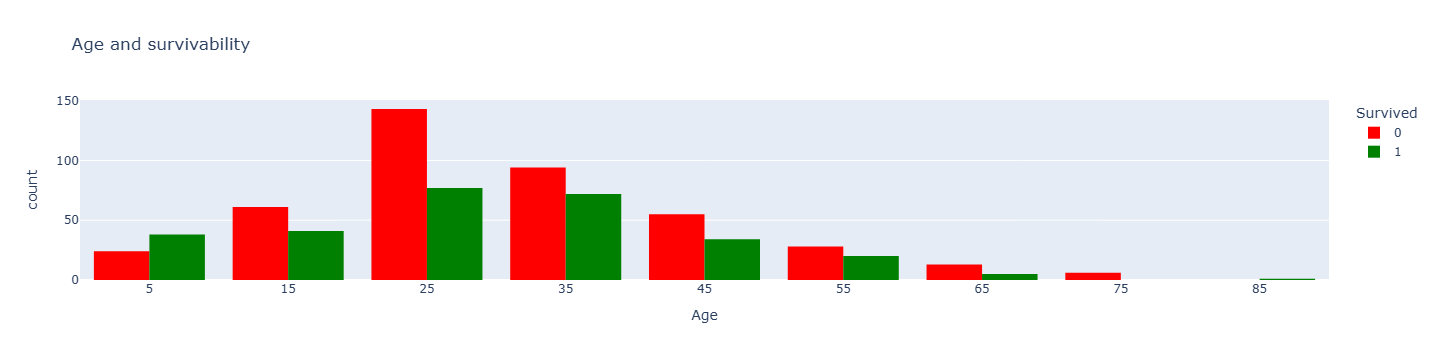

In [78]:
age_surv = px.histogram(
    df,
    x='Age',
    color_discrete_map={1:'green',0:'red'},
    color='Survived',
    barmode='group',
    title='Age and survivability',
)
age_surv.update_traces(
    xbins=dict(
    start=0,end=82,size=10),
    autobinx=False
                      )
age_surv.show()

# Sex and Survivability

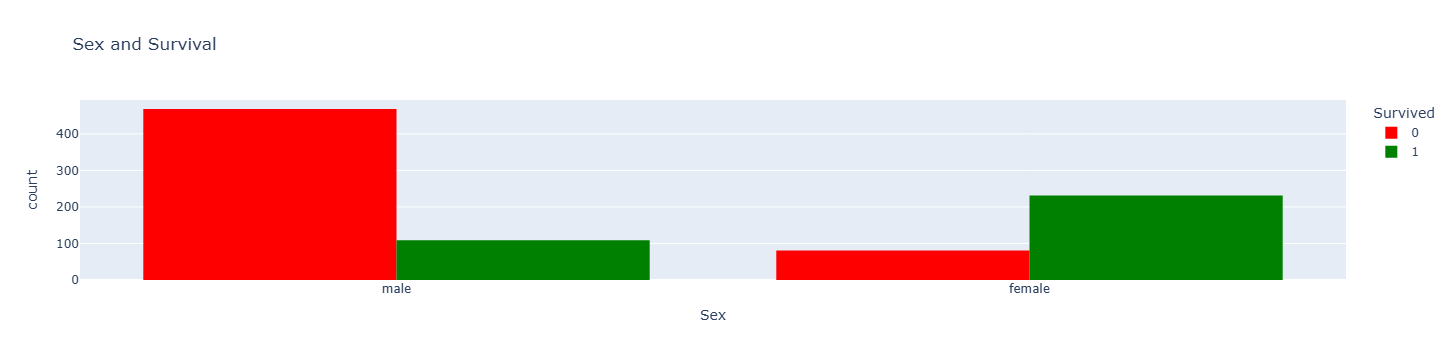

In [79]:
px.histogram(
    df,
    x='Sex',
    color = 'Survived',
    barmode='group',
    color_discrete_map={1:'green',0:'red'},
    title='Sex and Survival'
    
)

# Age, Sex and Survival

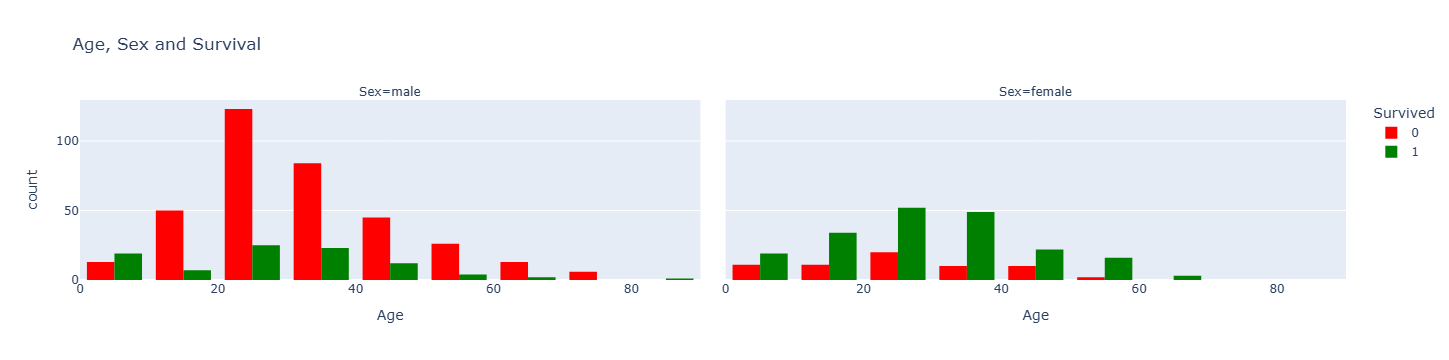

In [80]:
age_sx_surv = px.histogram(
    df,
    x='Age',
    color='Survived',
    barmode='group',
    color_discrete_map={1:'green',0:'red'},
    title='Age, Sex and Survival',
    facet_col='Sex'
            
)

age_sx_surv.update_traces(
    xbins = dict(
        start = 0, end = 82, size= 10
    )
)


# Class and Survival

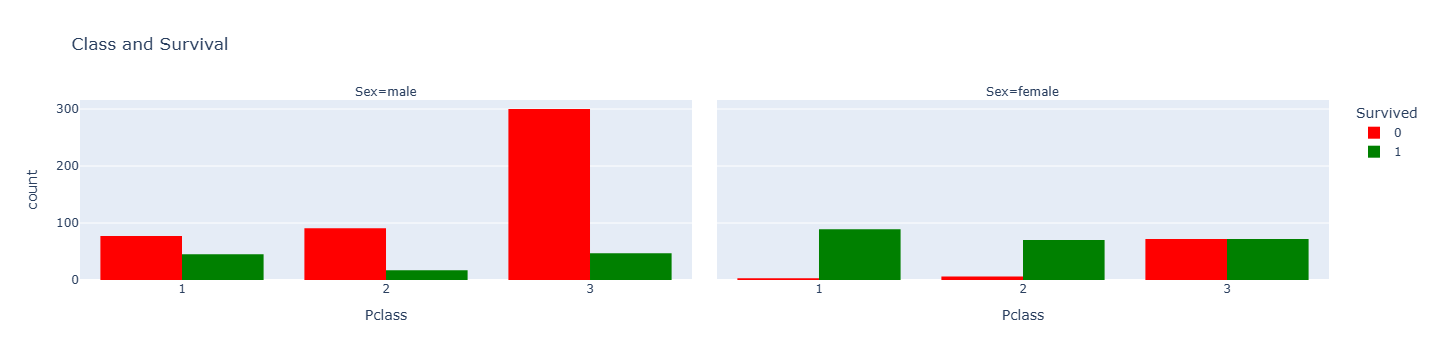

In [81]:
class_surv = px.histogram(
    df,
    x='Pclass',
    color='Survived',
    barmode='group',
    color_discrete_map={1:'green',0:'red'},
    title='Class and Survival',
    facet_col='Sex'
)
class_surv

# Cabin and Survival

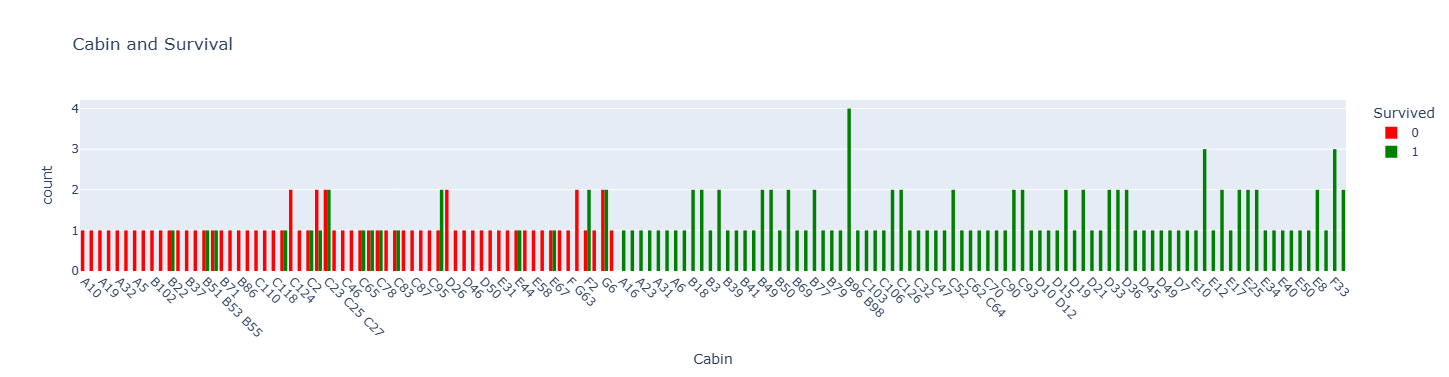

In [82]:
cabin_surv = px.histogram(
    df.sort_values(by='Cabin'),
    x='Cabin',
    color='Survived',
    color_discrete_map={1:'green',0:'red'},
    title="Cabin and Survival",
    barmode='group',
    width=2000
)
cabin_surv.update_xaxes(tickangle=45)
cabin_surv.show()

# Deck and Survival

In [83]:

df['Deck'] = df['Cabin'].str[0]


## Deck distribution among classes

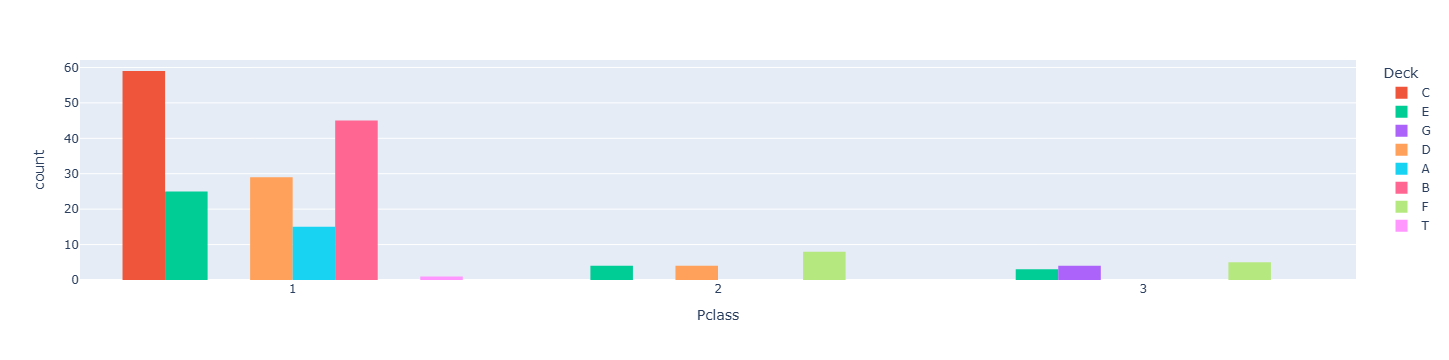

In [85]:
px.histogram(df,x='Pclass',color='Deck',barmode='group')

In [76]:
df[df['Deck'] == "T"] 

,Name,Sex,Age,SibSp,Parch,Embarked,Ticket,Fare,Cabin,PassengerId,Pclass,Survived,Deck
339,"Blackwell, Mr. Stephen Weart",male,45.0,0,0,S,113784,35.5,T,340,1,0,T


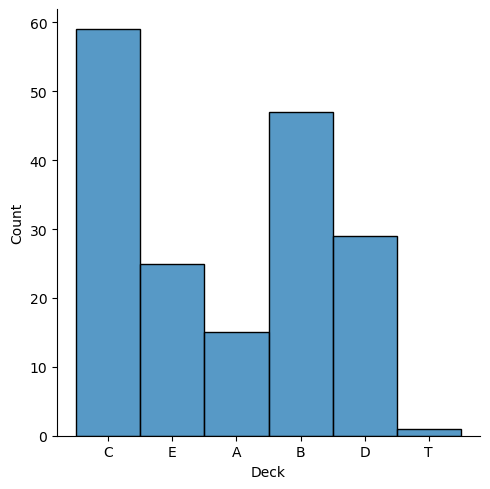

In [77]:
sns.displot(df[df['Pclass'] == 1],x='Deck')


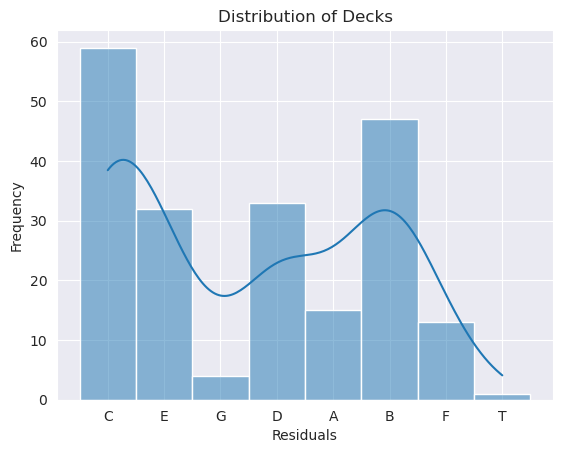

In [78]:
with sns.axes_style("darkgrid"):
    sns.histplot(df,x='Deck',kde=True,bins=30)
    plt.title("Distribution of Decks")
    plt.xlabel("Residuals")
    plt.ylabel("Frequency")

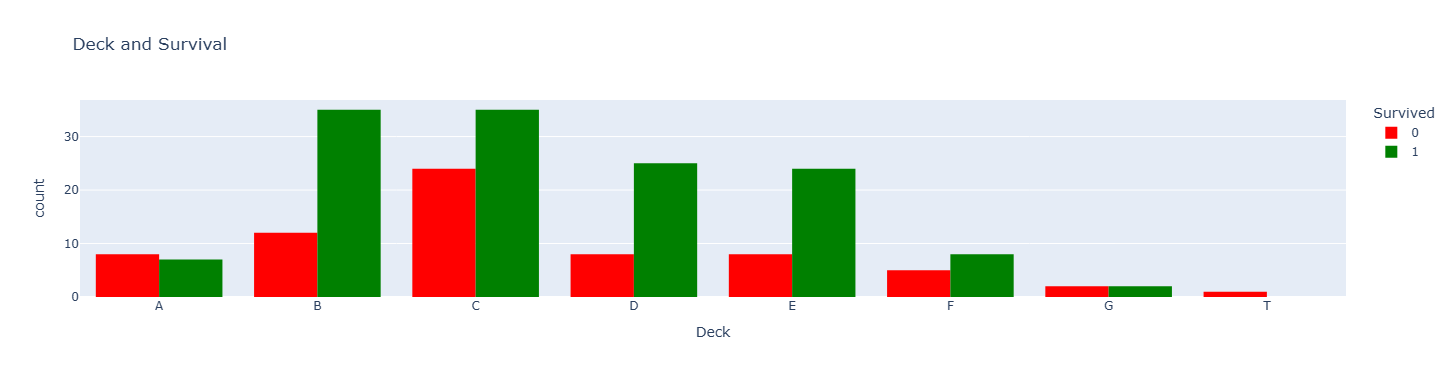

In [29]:
cabin_surv = px.histogram(
    df.sort_values(by='Deck'),
    x='Deck',
    color='Survived',
    color_discrete_map={1:'green',0:'red'},
    title="Deck and Survival",
    barmode='group',
    width=2000
)
cabin_surv.show()

# Embarked and Survival

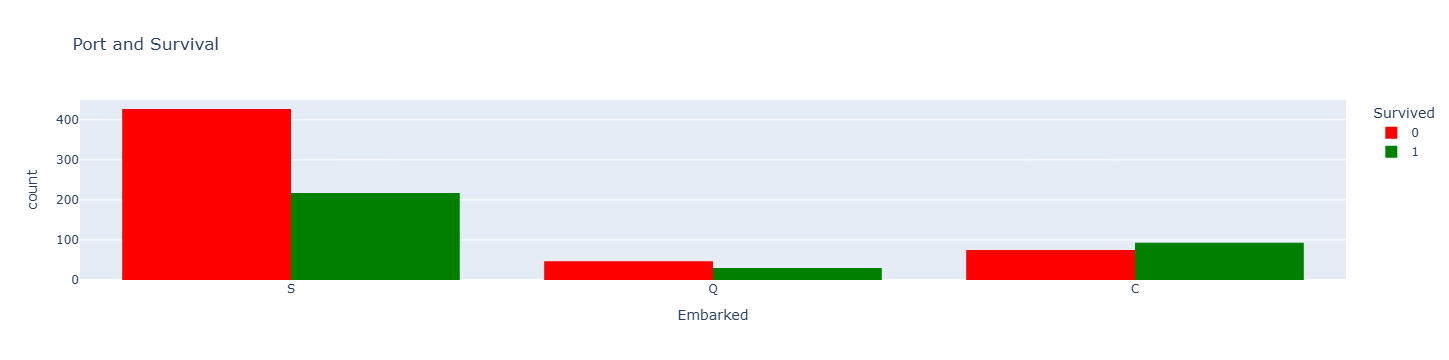

In [31]:
class_surv = px.histogram(
    df,
    x='Embarked',
    color='Survived',
    barmode='group',
    color_discrete_map={1:'green',0:'red'},
    title='Port and Survival',
)
class_surv

# fare and survival

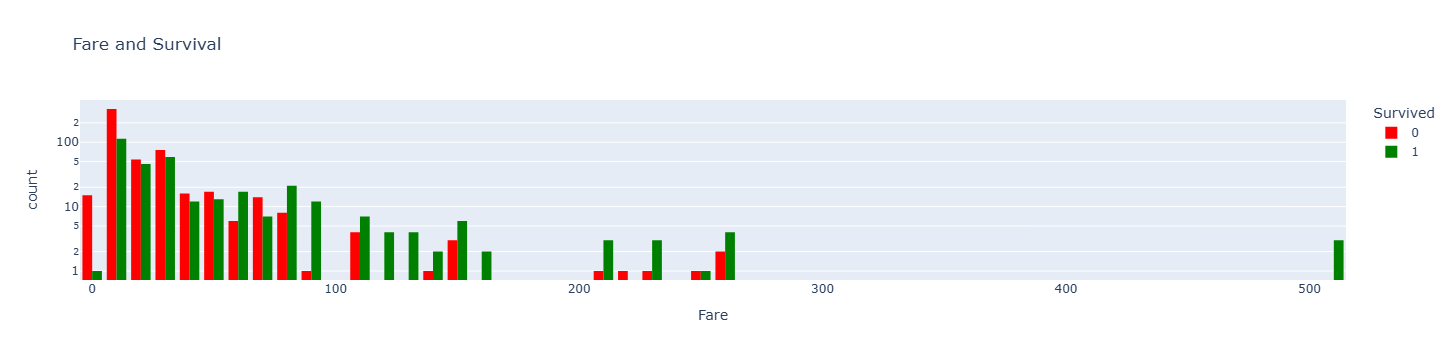

In [27]:
class_surv = px.histogram(
    df,
    x='Fare',
    color='Survived',
    barmode='group',
    color_discrete_map={1:'green',0:'red'},
    title='Fare and Survival',
    log_y=True
)
class_surv

# Fare and Class

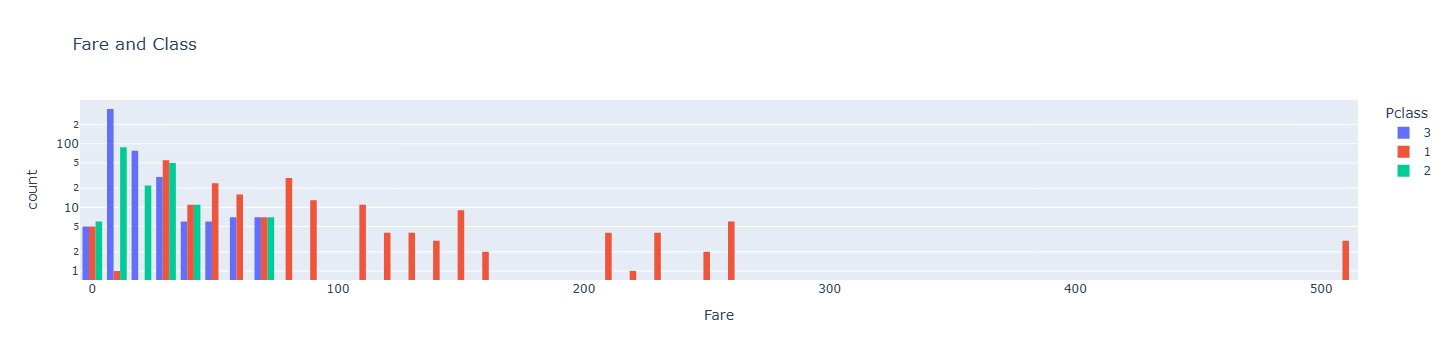

In [28]:
class_surv = px.histogram(
    df,
    x='Fare',
    color='Pclass',
    barmode='group',
    title='Fare and Class',
    log_y=True
)
class_surv

# Sib and Survival

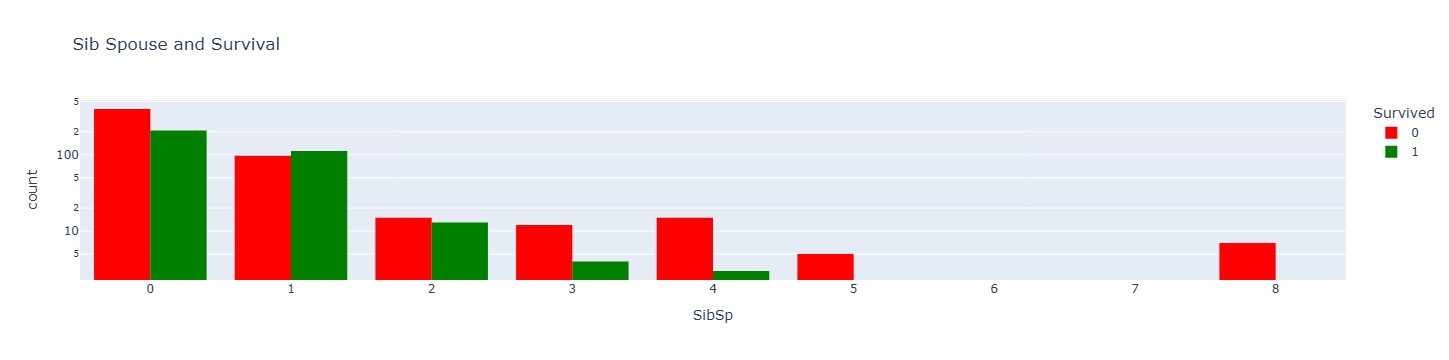

In [29]:
class_surv = px.histogram(
    df,
    x='SibSp',
    color='Survived', 
    barmode='group',
    title='Sib Spouse and Survival',
        color_discrete_map={1:'green',0:'red'},
    log_y=True
)
class_surv

# Par and Survival

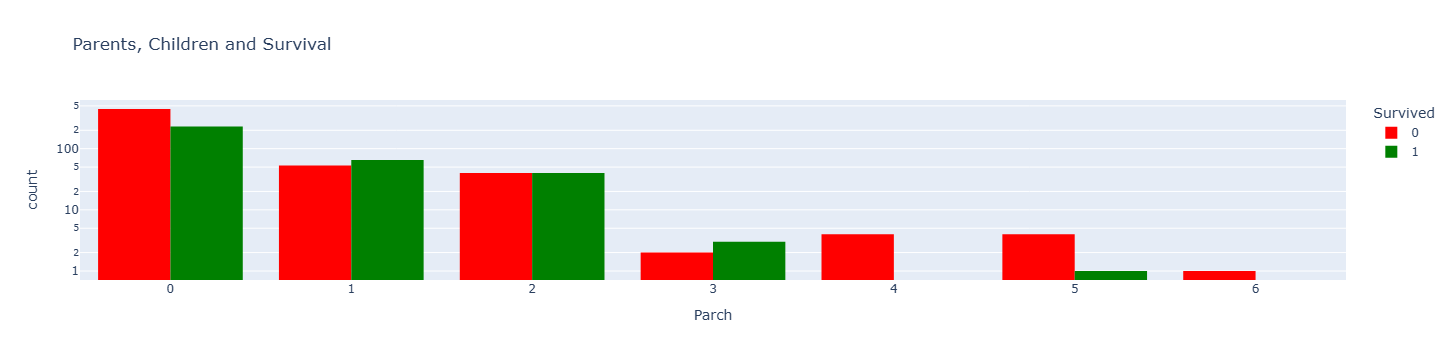

In [29]:
class_surv = px.histogram(
    df,
    x='Parch',
    color='Survived',
    barmode='group',
    title='Parents, Children and Survival',
        color_discrete_map={1:'green',0:'red'},
    log_y=True
)
class_surv

# Family Size col

In [2]:
df = pd.read_csv('Dataset/Titanic-Dataset.csv')

In [3]:
df

,Name,Sex,Age,SibSp,Parch,Embarked,Ticket,Fare,Cabin,PassengerId,Pclass,Survived
0,"Braund, Mr. Owen Harris",male,22.0,1,0,S,A/5 21171,7.2500,NaN,1,3,0
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,C,PC 17599,71.2833,C85,2,1,1
2,"Heikkinen, Miss. Laina",female,26.0,0,0,S,STON/O2. 3101282,7.9250,NaN,3,3,1
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,S,113803,53.1000,C123,4,1,1
4,"Allen, Mr. William Henry",male,35.0,0,0,S,373450,8.0500,NaN,5,3,0
...,...,...,...,...,...,...,...,...,...,...,...,...
886,"Montvila, Rev. Juozas",male,27.0,0,0,S,211536,13.0000,NaN,887,2,0
887,"Graham, Miss. Margaret Edith",female,19.0,0,0,S,112053,30.0000,B42,888,1,1
888,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,S,W./C. 6607,23.4500,NaN,889,3,0
889,"Behr, Mr. Karl Howell",male,26.0,0,0,C,111369,30.0000,C148,890,1,1


In [4]:
df['Family_Size'] = df['SibSp']+df['Parch']+1

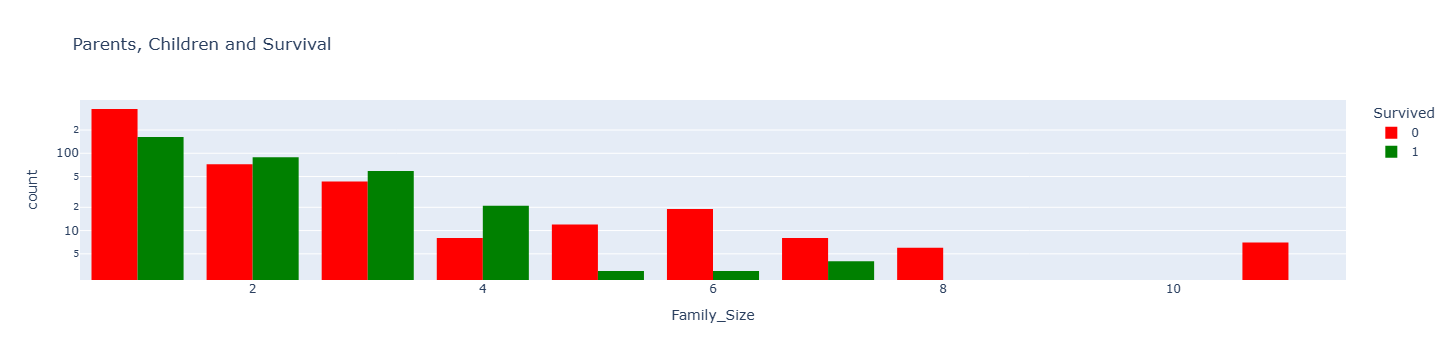

In [5]:
class_surv = px.histogram(
    df,
    x='Family_Size',
    color='Survived',
    barmode='group',
    title='Parents, Children and Survival',
        color_discrete_map={1:'green',0:'red'},
    log_y=True
)
class_surv

# Regression

In [6]:
from sklearn.model_selection import train_test_split


In [7]:
df.isna().sum()

Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Embarked         2
Ticket           0
Fare             0
Cabin          687
PassengerId      0
Pclass           0
Survived         0
Family_Size      0
dtype: int64

In [8]:
df['Deck'] = df['Cabin'].str[0]

In [46]:
from sklearn.preprocessing import OrdinalEncoder
from sklearn.impute import KNNImputer
enc = OrdinalEncoder()
drop_cols = ['Name','Ticket','Cabin','SibSp','Parch','PassengerId']
enc_data = df.drop(columns=drop_cols)
enc.fit(enc_data)
enc_data=enc.transform(enc_data)
enc_data
imputer = KNNImputer(n_neighbors=4)
enc_data = imputer.fit_transform(enc_data)
enc_data = pd.DataFrame(enc.inverse_transform(enc_data),index=df.index,columns=df.drop(columns=drop_cols).columns)
enc_data

,Sex,Age,Embarked,Fare,Pclass,Survived,Family_Size,Deck
0,male,22.0,S,7.25,3,0,2,E
1,female,38.0,C,71.2833,1,1,2,C
2,female,26.0,S,7.925,3,1,1,E
3,female,35.0,S,53.1,1,1,2,C
4,male,35.0,S,8.05,3,0,1,E
...,...,...,...,...,...,...,...,...
886,male,27.0,S,13.0,2,0,1,E
887,female,19.0,S,30.0,1,1,1,B
888,female,25.0,S,23.45,3,0,4,D
889,male,26.0,C,30.0,1,1,1,C


In [47]:
enc_data.isna().sum()

Sex            0
Age            0
Embarked       0
Fare           0
Pclass         0
Survived       0
Family_Size    0
Deck           0
dtype: int64

In [48]:
clean_df = enc_data

In [49]:
X = clean_df.drop(columns=['Survived'])
y = clean_df['Survived']
X

,Sex,Age,Embarked,Fare,Pclass,Family_Size,Deck
0,male,22.0,S,7.25,3,2,E
1,female,38.0,C,71.2833,1,2,C
2,female,26.0,S,7.925,3,1,E
3,female,35.0,S,53.1,1,2,C
4,male,35.0,S,8.05,3,1,E
...,...,...,...,...,...,...,...
886,male,27.0,S,13.0,2,1,E
887,female,19.0,S,30.0,1,1,B
888,female,25.0,S,23.45,3,4,D
889,male,26.0,C,30.0,1,1,C


## updated deck and survival stats

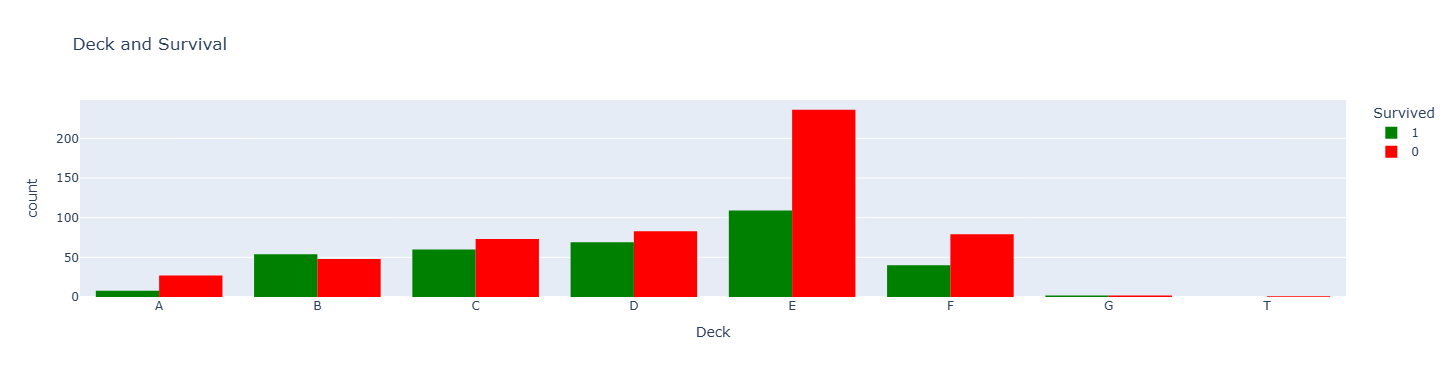

In [50]:
cabin_surv = px.histogram(
    clean_df.sort_values(by='Deck'),
    x='Deck',
    color='Survived',
    color_discrete_map={1:'green',0:'red'},
    title="Deck and Survival",
    barmode='group',
    width=2000
)
cabin_surv.show()

In [51]:
from sklearn.preprocessing import OneHotEncoder
enc = OneHotEncoder()
cat_col = X[['Sex','Embarked','Deck']]
enc.fit(cat_col)
X_enc = enc.transform(cat_col)
X_df = pd.DataFrame(X_enc.toarray(), columns=enc.get_feature_names_out())


In [52]:
X_df

,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S,Deck_A,Deck_B,Deck_C,Deck_D,Deck_E,Deck_F,Deck_G,Deck_T
0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
887,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
888,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
889,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


In [53]:
X = pd.concat([X.drop(columns=['Sex','Embarked','Deck']),X_df],axis=1)
X

,Age,Fare,Pclass,Family_Size,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S,Deck_A,Deck_B,Deck_C,Deck_D,Deck_E,Deck_F,Deck_G,Deck_T
0,22.0,7.25,3,2,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,38.0,71.2833,1,2,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2,26.0,7.925,3,1,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,35.0,53.1,1,2,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,35.0,8.05,3,1,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,27.0,13.0,2,1,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
887,19.0,30.0,1,1,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
888,25.0,23.45,3,4,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
889,26.0,30.0,1,1,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


In [54]:
X

,Age,Fare,Pclass,Family_Size,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S,Deck_A,Deck_B,Deck_C,Deck_D,Deck_E,Deck_F,Deck_G,Deck_T
0,22.0,7.25,3,2,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,38.0,71.2833,1,2,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2,26.0,7.925,3,1,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,35.0,53.1,1,2,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,35.0,8.05,3,1,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,27.0,13.0,2,1,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
887,19.0,30.0,1,1,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
888,25.0,23.45,3,4,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
889,26.0,30.0,1,1,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


In [55]:
y = y.astype(int)
num_col = ['Age','Fare','Family_Size']
X[num_col] = X[num_col].apply(pd.to_numeric)
X['Pclass'] = X['Pclass'].astype(int)

In [56]:
from sklearn.linear_model import LogisticRegression
regression = LogisticRegression(max_iter=2000)

In [57]:
def final_pipeline(X,y,mtype,shap=False):
    X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.1,random_state=10,stratify=y)
    model = mtype.fit(X_train,(y_train)) 
    if mtype == 'regression':
        print(f'The regression coeffiecient table is:\n{pd.DataFrame(model.coef_.T,index=X_train.columns,columns=['Coeffs'])}')
        print(f'The model intercept is :{model.intercept_} and model score for training data is {model.score(X_train,y_train)}')
    y_pred = model.predict(X_test)
    print(f'The classification report is :\n{classification_report(y_test,y_pred)}')
    print(f'The confusion matrix is :\n{confusion_matrix(y_test,y_pred)}')
    # SHAP VISUALISATION
    if shap:
        print(X.dtypes)
        explainer = shap.Explainer(model.predict, X_train)
        shap_values = explainer(X_test)
        shap.initjs()
        shap.waterfall_plot(shap_values[0])
    

In [58]:
final_pipeline(X,y,regression)

The classification report is :
              precision    recall  f1-score   support

           0       0.84      0.85      0.85        55
           1       0.76      0.74      0.75        35

    accuracy                           0.81        90
   macro avg       0.80      0.80      0.80        90
weighted avg       0.81      0.81      0.81        90

The confusion matrix is :
[[47  8]
 [ 9 26]]


## Scaling 

<Axes: xlabel='Age', ylabel='Count'>

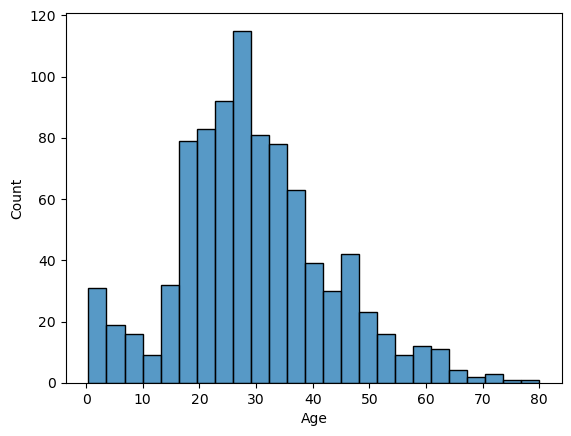

In [23]:
sns.histplot(X,x='Age')

In [26]:
X['Age'].sort_values()
X_norm['Age'].sort_values()

NameError: name 'X_norm' is not defined

In [27]:
X_norm = pd.concat([pd.DataFrame(normalize(X[num_col],axis=0),columns=X[num_col].columns),X.drop(columns=num_col)],axis=1)
X_norm

,Age,Fare,Family_Size,Pclass,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S,Deck_A,Deck_B,Deck_C,Deck_D,Deck_E,Deck_F,Deck_G,Deck_T
0,0.022644,0.004103,0.026849,3,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,0.039113,0.040344,0.026849,1,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2,0.026761,0.004485,0.013424,3,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,0.036025,0.030053,0.026849,1,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,0.036025,0.004556,0.013424,3,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0.027791,0.007358,0.013424,2,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
887,0.019556,0.016979,0.013424,1,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
888,0.021100,0.013272,0.053697,3,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
889,0.026761,0.016979,0.013424,1,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


The regression coeffiecient table is:
               Coeffs
Age         -0.617731
Fare         0.306451
Family_Size -0.149799
Pclass      -1.236410
Sex_female   1.280971
Sex_male    -1.278182
Embarked_C   0.253660
Embarked_Q  -0.012811
Embarked_S  -0.238060
Deck_A      -0.574593
Deck_B      -0.228132
Deck_C      -0.301017
Deck_D       0.020571
Deck_E       0.266327
Deck_F       0.712848
Deck_G       0.445563
Deck_T      -0.338777
The model intercept is :[2.53394803] and model score for training data is 0.8061797752808989
The classification report is :
              precision    recall  f1-score   support

           0       0.83      0.86      0.84       110
           1       0.77      0.71      0.74        69

    accuracy                           0.80       179
   macro avg       0.80      0.79      0.79       179
weighted avg       0.80      0.80      0.80       179

The confusion matrix is :
[[95 15]
 [20 49]]
Age            float64
Fare           float64
Family_Size    float64
P

PermutationExplainer explainer: 180it [00:17,  4.33it/s]                                                               


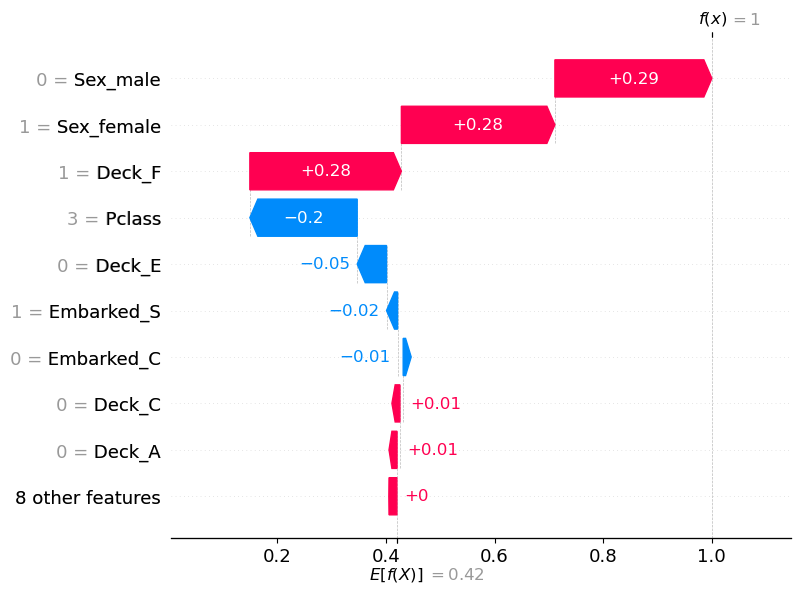

In [48]:
final_pipeline(X_norm,y,regression)

## Using Standard Scalar

In [59]:
scalar = StandardScaler().fit(X[num_col])
X_stand = scalar.transform(X[num_col])
X_stand = pd.concat([pd.DataFrame(X_stand,columns=X[num_col].columns),X.drop(columns=num_col)],axis=1)
X_stand


,Age,Fare,Family_Size,Pclass,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S,Deck_A,Deck_B,Deck_C,Deck_D,Deck_E,Deck_F,Deck_G,Deck_T
0,-0.581705,-0.502445,0.059160,3,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,0.603288,0.786845,0.059160,1,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2,-0.285457,-0.488854,-0.560975,3,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,0.381102,0.420730,0.059160,1,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,0.381102,-0.486337,-0.560975,3,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,-0.211394,-0.386671,-0.560975,2,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
887,-0.803891,-0.044381,-0.560975,1,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
888,-0.359519,-0.176263,1.299429,3,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
889,-0.285457,-0.044381,-0.560975,1,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


In [60]:
final_pipeline(X_stand,y,regression)

The classification report is :
              precision    recall  f1-score   support

           0       0.84      0.85      0.85        55
           1       0.76      0.74      0.75        35

    accuracy                           0.81        90
   macro avg       0.80      0.80      0.80        90
weighted avg       0.81      0.81      0.81        90

The confusion matrix is :
[[47  8]
 [ 9 26]]


# Outlier

In [143]:
X_train.dtypes

Age            float64
Fare           float64
Pclass          object
Family_Size      int64
Sex_female     float64
Sex_male       float64
Embarked_C     float64
Embarked_Q     float64
Embarked_S     float64
Deck_A         float64
Deck_B         float64
Deck_C         float64
Deck_D         float64
Deck_E         float64
Deck_F         float64
Deck_G         float64
Deck_T         float64
dtype: object

In [142]:
X_train[num_col] = X_train[num_col].apply(pd.to_numeric)

<Axes: >

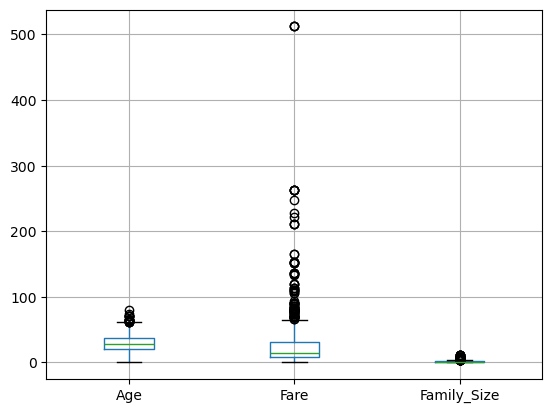

In [144]:
X_train.boxplot(column=num_col)

Axes(0.125,0.11;0.775x0.77)


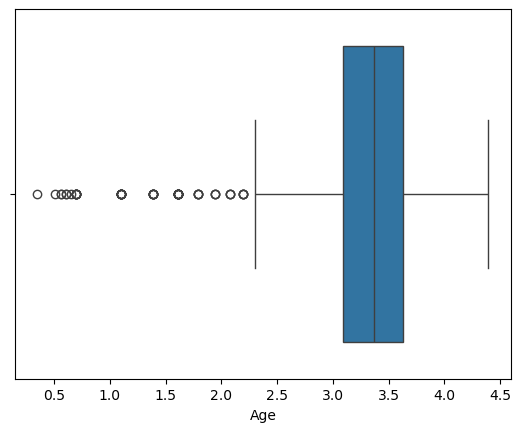

Axes(0.125,0.11;0.775x0.77)


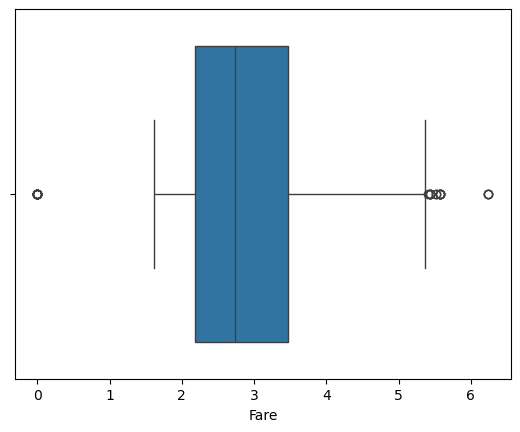

Axes(0.125,0.11;0.775x0.77)


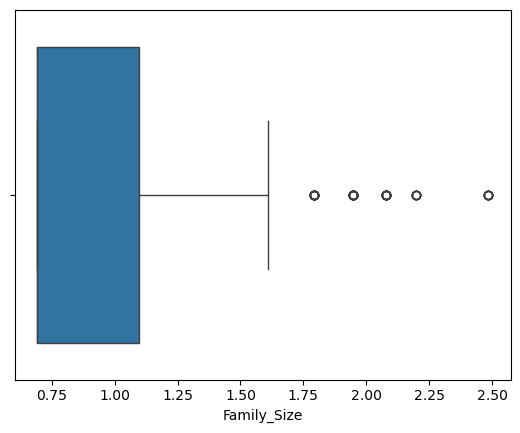

In [166]:
for col in num_col:
    print(sns.boxplot(X_log,x=col))
    plt.show()

# log transfrom

In [159]:
X[num_col].dtypes

Age            float64
Fare           float64
Family_Size      int64
dtype: object

In [50]:
X_log = np.log(X[num_col]+1)
X_log = pd.concat([pd.DataFrame(X_log,columns=X[num_col].columns),X.drop(columns=num_col)],axis=1)
X_log


,Age,Fare,Family_Size,Pclass,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S,Deck_A,Deck_B,Deck_C,Deck_D,Deck_E,Deck_F,Deck_G,Deck_T
0,3.135494,2.110213,1.098612,3,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,3.663562,4.280593,1.098612,1,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2,3.295837,2.188856,0.693147,3,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,3.583519,3.990834,1.098612,1,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,3.583519,2.202765,0.693147,3,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,3.332205,2.639057,0.693147,2,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
887,2.995732,3.433987,0.693147,1,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
888,3.068053,3.196630,1.609438,3,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
889,3.295837,3.433987,0.693147,1,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


In [164]:
final_pipeline(X_log,y,regression)

The regression coeffiecient table is:
               Coeffs
Age         -0.927175
Fare         0.394865
Family_Size -0.852394
Pclass      -1.159204
Sex_female   1.305421
Sex_male    -1.301762
Embarked_C   0.096396
Embarked_Q   0.111632
Embarked_S  -0.204368
Deck_A      -0.485392
Deck_B      -0.017487
Deck_C      -0.383584
Deck_D       0.049613
Deck_E       0.267326
Deck_F       0.520739
Deck_G       0.431607
Deck_T      -0.379164
The model intercept is :[5.07109904] and model score for training data is 0.8230337078651685
The classification report is :
              precision    recall  f1-score   support

           0       0.84      0.88      0.86       110
           1       0.80      0.74      0.77        69

    accuracy                           0.83       179
   macro avg       0.82      0.81      0.81       179
weighted avg       0.83      0.83      0.83       179

The confusion matrix is :
[[97 13]
 [18 51]]


In [61]:
bst = XGBClassifier(n_estimators=320, max_depth=4, learning_rate=0.05, subsample=0.8,colsample_bytree=0.8 )
final_pipeline(X_stand,y,bst)

The classification report is :
              precision    recall  f1-score   support

           0       0.83      0.91      0.87        55
           1       0.83      0.71      0.77        35

    accuracy                           0.83        90
   macro avg       0.83      0.81      0.82        90
weighted avg       0.83      0.83      0.83        90

The confusion matrix is :
[[50  5]
 [10 25]]
